# Step 4: Diameter regression

**Client:** NASA/JPL Planetary Defense Coordination Office (PDCO)
**Why the diameter?** It sets the severity of an impact: the energy scales with the diameter **cubed**. Yet 97% of the diameters in the catalogue are not measured but computed from H with a fixed albedo of 0.14.

**The two questions of this step:**

1. Can we estimate the diameter **better** than the fixed-albedo formula, by learning from the 1,244 actually measured diameters?
2. What is the **uncertainty** of that estimate? For a "zero false negative" policy, we need the *maximum plausible* size of an object, not just its average size.

This notebook uses the data prepared in step 3: run `03_preprocessing.ipynb` first.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GridSearchCV, KFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor, plot_tree

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

def find_project_dir() -> Path:
    for base in [Path.cwd(), *Path.cwd().parents]:
        for candidate in (base, base / "nasa-project"):
            if (candidate / "data" / "raw").is_dir():
                return candidate
    raise FileNotFoundError("Folder nasa-project/data/raw not found.")

PROJECT_DIR = find_project_dir()
RAW_DIR = PROJECT_DIR / "data" / "raw"
PREP_DIR = PROJECT_DIR / "data" / "processed" / "03_preprocessing"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed" / "04_diameter"
REPORT_DIR = PROJECT_DIR / "reports" / "04_diameter"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

if not (PREP_DIR / "diameter_train.csv").exists():
    raise FileNotFoundError("Run 03_preprocessing.ipynb first.")

config = json.loads((PROJECT_DIR / "reports" / "03_preprocessing" / "preprocessing_config.json").read_text(encoding="utf-8"))
RANDOM_STATE = config["random_state"]
NUM = config["diameter_regression"]["features"]["numeric"]
CAT = config["diameter_regression"]["features"]["categorical"]
FEATURES = NUM + CAT
TARGET = config["diameter_regression"]["target"]

train = pd.read_csv(PREP_DIR / "diameter_train.csv")
test = pd.read_csv(PREP_DIR / "diameter_test.csv")
preprocessor = joblib.load(PREP_DIR / "preprocessor_diameter.joblib")   # unfitted

BLUE, ORANGE, GREY, RED, GREEN = "#2878B5", "#E07A2D", "#8C8C8C", "#C0392B", "#3A8F5C"
LABEL_BOX = dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.5)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})

def save(fig, name):
    fig.savefig(REPORT_DIR / f"{name}.png", dpi=160, bbox_inches="tight")

def fmt(n):
    return f"{n:,.0f}"

print(f"Features: {FEATURES} | target: {TARGET}")
print(f"Train: {len(train)} objects | Test: {len(test)} objects")

Features: ['H', 'a', 'e', 'i', 'q', 'ad', 'class'] | target: log10_diameter_km
Train: 995 objects | Test: 249 objects


## 1. Starting from physics

The relation between the diameter D (km), the absolute magnitude H and the albedo p is known:

$$\log_{10} D = \underbrace{\log_{10} 1329 - \tfrac{1}{2}\log_{10} p}_{\text{albedo term, unknown}} \;-\; \underbrace{H/5}_{\text{known exactly}}$$

The only unknown is the albedo. Two strategies are therefore possible:

- **Direct**: the model predicts log₁₀ D from H and the orbit. It has to relearn the −1/5 slope on H.
- **Physics-guided**: we keep the exact −H/5 term, and the model only predicts the **albedo term** `r = log₁₀ D + H/5`. It thus learns *how dark or bright the object is*, from its orbit and size.

The second one is especially suited to trees: a tree approximates a straight line with steps, whereas it handles an albedo term that varies little very well.

In [2]:
LOG_K = np.log10(1329)

def albedo_term(df):
    return df[TARGET] + df["H"] / 5

def to_log_diameter(albedo_term_pred, H):
    return albedo_term_pred - H / 5

def term_to_albedo(term):
    return 10 ** (2 * (LOG_K - term))

y_train, y_test = train[TARGET], test[TARGET]
r_train = albedo_term(train)

def metrics(y_true, y_pred) -> dict:
    err = np.asarray(y_pred) - np.asarray(y_true)
    return {
        "RMSE (dex)": np.sqrt(np.mean(err ** 2)),
        "R²": 1 - np.sum(err ** 2) / np.sum((y_true - np.mean(y_true)) ** 2),
        "median error factor": 10 ** np.median(np.abs(err)),
        "% within ±30%": np.mean(np.abs(err) < np.log10(1.3)) * 100,
        "% off by a factor > 2": np.mean(np.abs(err) > np.log10(2)) * 100,
        "bias (dex)": np.mean(err),
    }

**How to read the metrics:**

- **RMSE in dex**: average error on log₁₀ D. An error of 0.2 dex corresponds to a factor 10^0.2 ≈ 1.6 on the diameter.
- **Median error factor**: for half of the objects, the predicted diameter is within this factor of the true diameter (1.4 = ±40%).
- **% off by a factor > 2**: the share of severe errors, the ones that matter for the PDCO.
- **R²**: it looks high (≈ 0.8) as soon as H is used, because H alone explains most of the size differences. The comparison with the reference formula is what tells whether the model adds anything.

## 2. Model comparison with cross-validation (training set only)

5-fold cross-validation on the training set. The test set is used only once, in section 3.

In [3]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def pipe(model):
    return Pipeline([("prep", clone(preprocessor)), ("model", model)])

candidates = {
    "Catalogue formula (albedo 0.14)": None,
    "Learned mean albedo": ("residual", pipe(DummyRegressor())),
    "Direct linear": ("direct", pipe(LinearRegression())),
    "Direct tree (depth 6)": ("direct", pipe(DecisionTreeRegressor(max_depth=6, min_samples_leaf=10, random_state=RANDOM_STATE))),
    "Physics-guided tree (depth 3)": ("residual", pipe(DecisionTreeRegressor(max_depth=3, min_samples_leaf=20, random_state=RANDOM_STATE))),
    "Physics-guided Random Forest": ("residual", pipe(RandomForestRegressor(n_estimators=400, min_samples_leaf=10, max_features=0.5, n_jobs=-1, random_state=RANDOM_STATE))),
}

cv_rows, oof = [], {}
for name, spec in candidates.items():
    if spec is None:
        pred = np.log10(1329 / np.sqrt(0.14)) - train["H"] / 5
    else:
        kind, model = spec
        if kind == "direct":
            pred = cross_val_predict(model, train[FEATURES], y_train, cv=cv)
        else:
            pred = to_log_diameter(cross_val_predict(model, train[FEATURES], r_train, cv=cv), train["H"])
    oof[name] = np.asarray(pred)
    cv_rows.append({"model": name, **metrics(y_train, pred)})

cv_table = pd.DataFrame(cv_rows).set_index("model")
cv_table.to_csv(REPORT_DIR / "model_comparison_cv.csv")
cv_table.round(3)

,RMSE (dex),R²,median error factor,% within ±30%,% off by a factor > 2,bias (dex)
model,,,,,,
Catalogue formula (albedo 0.14),0.219,0.797,1.438,36.784,17.387,-0.045
Learned mean albedo,0.215,0.805,1.475,34.171,15.075,0.000
Direct linear,0.198,0.834,1.409,38.291,11.759,0.001
Direct tree (depth 6),0.223,0.789,1.410,39.598,17.990,-0.001
Physics-guided tree (depth 3),0.202,0.827,1.408,38.291,12.060,-0.002
Physics-guided Random Forest,0.195,0.839,1.379,39.397,10.955,-0.001


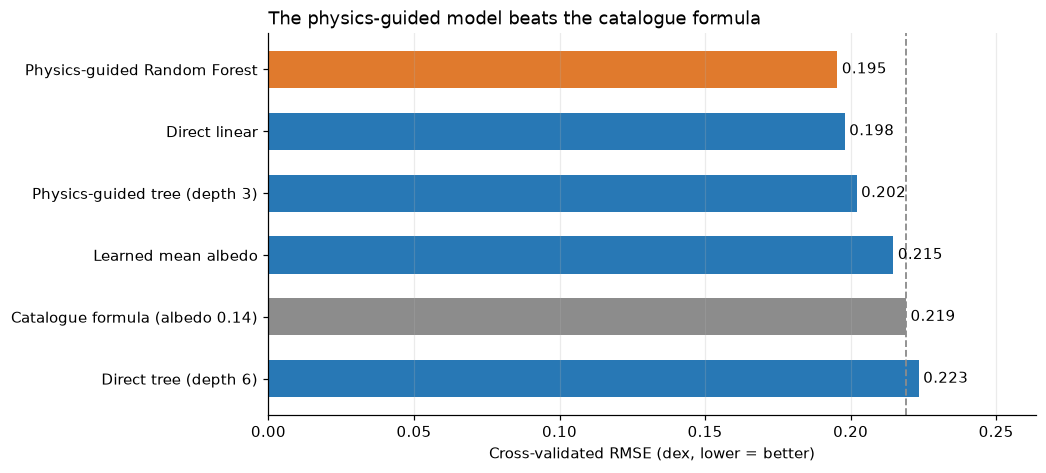

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
order = cv_table["RMSE (dex)"].sort_values(ascending=False)
colors = [GREY if "formula" in n else (ORANGE if "Random Forest" in n else BLUE) for n in order.index]
bars = ax.barh(order.index, order.values, color=colors, height=0.6)
ax.bar_label(bars, labels=[f"{v:.3f}" for v in order.values], padding=3)
ref = cv_table.loc["Catalogue formula (albedo 0.14)", "RMSE (dex)"]
ax.axvline(ref, color=GREY, ls="--", lw=1.2)
ax.set_xlim(0, order.max() * 1.18)
ax.set_xlabel("Cross-validated RMSE (dex, lower = better)")
ax.set_title("The physics-guided model beats the catalogue formula", loc="left")
ax.grid(axis="y", visible=False)
save(fig, "model_comparison_cv")
plt.show()

**Reading:**

- **The direct tree is the worst**, even worse than the formula itself: it approximates the line log D = f(H) with steps. This justifies the physics-guided approach.
- **Learning the mean albedo of the measured objects** already corrects the formula's bias: measured objects are on average slightly darker than 0.14.
- **The physics-guided Random Forest** has the lowest error. The gain over the formula is real but modest: an asteroid's albedo can only partly be inferred from its orbit.

We now tune the Random Forest hyperparameters with a grid search, still cross-validated on the training set.

In [5]:
grid = GridSearchCV(
    pipe(RandomForestRegressor(n_estimators=400, n_jobs=-1, random_state=RANDOM_STATE)),
    param_grid={"model__min_samples_leaf": [5, 10, 20, 40], "model__max_features": [0.3, 0.5, 1.0]},
    cv=cv, scoring="neg_root_mean_squared_error", n_jobs=1,
)
grid.fit(train[FEATURES], r_train)   # RMSE on the albedo term = RMSE on log D (same exact offset)

grid_results = (pd.DataFrame(grid.cv_results_)
                .assign(RMSE=lambda d: -d["mean_test_score"])
                [["param_model__min_samples_leaf", "param_model__max_features", "RMSE", "std_test_score"]]
                .sort_values("RMSE"))
grid_results.to_csv(REPORT_DIR / "rf_grid_search.csv", index=False)
print("Best parameters:", grid.best_params_, f"| CV RMSE = {-grid.best_score_:.3f} dex")
grid_results.head(5)

Best parameters: {'model__max_features': 1.0, 'model__min_samples_leaf': 20} | CV RMSE = 0.195 dex


,param_model__min_samples_leaf,param_model__max_features,RMSE,std_test_score
10,20,1.000,0.195,0.015
9,10,1.000,0.195,0.014
5,10,0.500,0.195,0.014
6,20,0.500,0.195,0.015
1,10,0.300,0.195,0.014


## 3. Final evaluation on the test set (once)

The three reference models are retrained on **the whole training set**, then evaluated on the 249 test objects, never seen before.

In [6]:
final_models = {
    "Catalogue formula (albedo 0.14)": None,
    "Direct linear": ("direct", pipe(LinearRegression()).fit(train[FEATURES], y_train)),
    "Physics-guided Random Forest": ("residual", grid.best_estimator_),
}

def predict_log_d(spec, df):
    if spec is None:
        return np.log10(1329 / np.sqrt(0.14)) - df["H"] / 5
    kind, model = spec
    pred = model.predict(df[FEATURES])
    return pred if kind == "direct" else to_log_diameter(pred, df["H"])

test_preds = {name: np.asarray(predict_log_d(spec, test)) for name, spec in final_models.items()}
test_table = pd.DataFrame([{"model": n, **metrics(y_test, p)} for n, p in test_preds.items()]).set_index("model")
test_table.to_csv(REPORT_DIR / "test_metrics.csv")

gain = 1 - test_table.loc["Physics-guided Random Forest", "RMSE (dex)"] / test_table.loc["Catalogue formula (albedo 0.14)", "RMSE (dex)"]
print(f"RMSE reduction compared with the catalogue formula: {gain:.0%}")
test_table.round(3)

RMSE reduction compared with the catalogue formula: 9%


,RMSE (dex),R²,median error factor,% within ±30%,% off by a factor > 2,bias (dex)
model,,,,,,
Catalogue formula (albedo 0.14),0.222,0.811,1.472,35.743,20.080,-0.055
Direct linear,0.200,0.847,1.435,36.546,11.245,-0.016
Physics-guided Random Forest,0.203,0.842,1.430,36.948,12.048,-0.019


**Honest reading of the test:**

- **Against the catalogue formula**, the gain is clear on severe errors: the share of diameters off by a factor greater than 2 drops from about **20% to 12%**. The bias (systematic underestimation by the formula) is also reduced.
- **Between the Random Forest and the linear model**, the test gap is smaller than the fold-to-fold variability seen in cross-validation (± 0.015 dex). Both models are therefore **tied on accuracy**.
- **We keep the Random Forest** for a reason these metrics do not show: its behavior on small objects, absent from the training data (section 6).

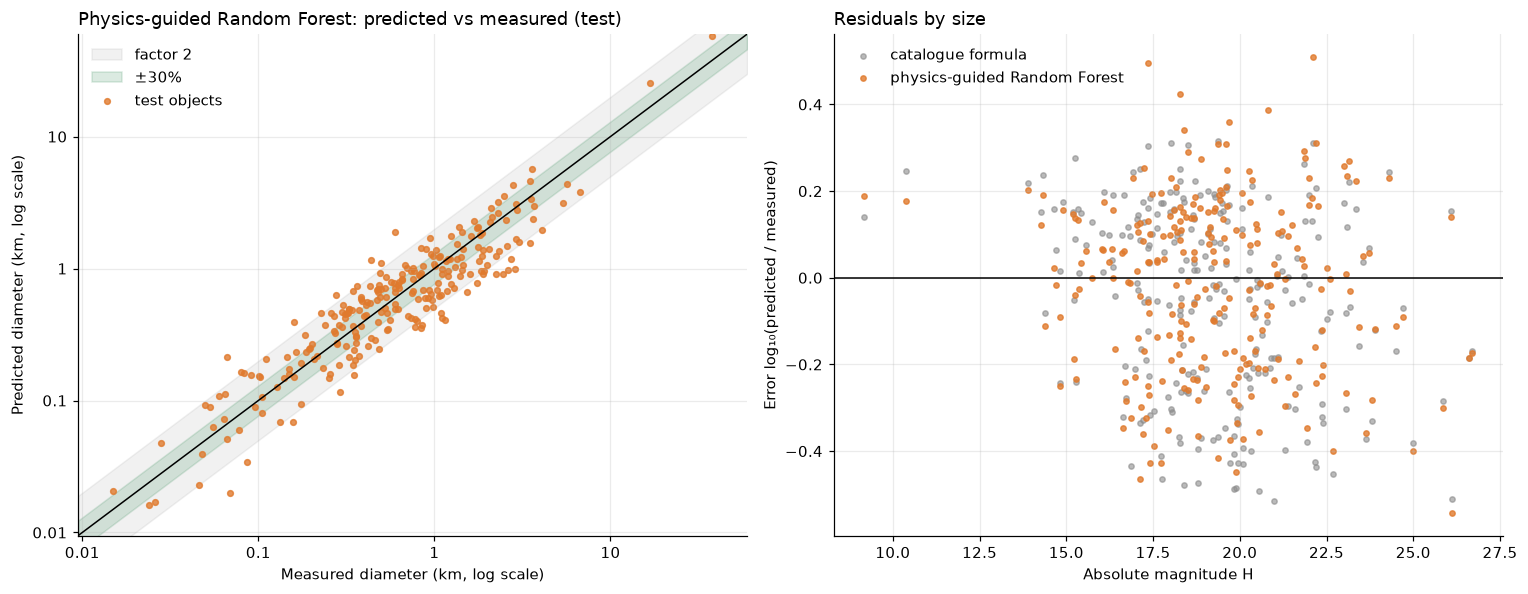

In [7]:
best = test_preds["Physics-guided Random Forest"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

ax = axes[0]
lims = np.array([y_test.min() - 0.2, y_test.max() + 0.2])
ax.fill_between(lims, lims - np.log10(2), lims + np.log10(2), color=GREY, alpha=0.12, label="factor 2")
ax.fill_between(lims, lims - np.log10(1.3), lims + np.log10(1.3), color=GREEN, alpha=0.18, label="±30%")
ax.plot(lims, lims, color="black", lw=1)
ax.scatter(y_test, best, s=14, color=ORANGE, alpha=0.8, label="test objects")
ticks = np.arange(np.floor(lims[0]), np.ceil(lims[1]) + 1)
ax.set_xticks(ticks, [f"{10**t:g}" for t in ticks])
ax.set_yticks(ticks, [f"{10**t:g}" for t in ticks])
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("Measured diameter (km, log scale)")
ax.set_ylabel("Predicted diameter (km, log scale)")
ax.set_title("Physics-guided Random Forest: predicted vs measured (test)", loc="left")
ax.legend(frameon=False, loc="upper left")

ax = axes[1]
err_formula = test_preds["Catalogue formula (albedo 0.14)"] - y_test
err_rf = best - y_test
ax.axhline(0, color="black", lw=1)
ax.scatter(test["H"], err_formula, s=12, color=GREY, alpha=0.6, label="catalogue formula")
ax.scatter(test["H"], err_rf, s=12, color=ORANGE, alpha=0.8, label="physics-guided Random Forest")
ax.set_xlabel("Absolute magnitude H")
ax.set_ylabel("Error log₁₀(predicted / measured)")
ax.set_title("Residuals by size", loc="left")
ax.legend(frameon=False)
fig.tight_layout()
save(fig, "predicted_vs_measured_test")
plt.show()

## 4. What the model learned

**Permutation importance** (on the test set): we shuffle one variable at a time and measure the increase in error. The larger the increase, the more the model relies on that variable.

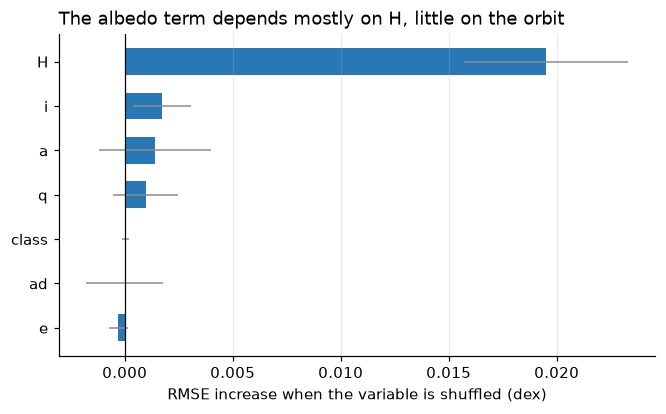

In [8]:
perm = permutation_importance(grid.best_estimator_, test[FEATURES], albedo_term(test),
                              scoring="neg_root_mean_squared_error", n_repeats=20,
                              random_state=RANDOM_STATE)
importance = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
importance.rename("RMSE increase (dex)").to_csv(REPORT_DIR / "permutation_importance.csv")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(importance.index, importance.values, xerr=perm.importances_std[np.argsort(perm.importances_mean)],
        color=BLUE, height=0.6, error_kw={"ecolor": GREY, "lw": 1})
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("RMSE increase when the variable is shuffled (dex)")
ax.set_title("The albedo term depends mostly on H, little on the orbit", loc="left")
ax.grid(axis="y", visible=False)
save(fig, "permutation_importance")
plt.show()

**Reading:** H remains the most useful variable, even to predict the albedo. Among measured objects, small ones are on average darker than large ones. There are two possible explanations, which we cannot separate here:

- a real physical effect (different composition depending on size);
- a **selection bias**: infrared measurements (NEOWISE) detect small dark objects better, as they emit more heat for their brightness.

The orbit only adds a small complement in the forest. This is an honest result to present: **the albedo of a near-Earth object is hard to infer from its orbit.**

For the presentation, here is a shallow tree trained on the raw variables. It is less accurate than the forest, but its rules can be read directly. Leaf values have been converted to albedo.

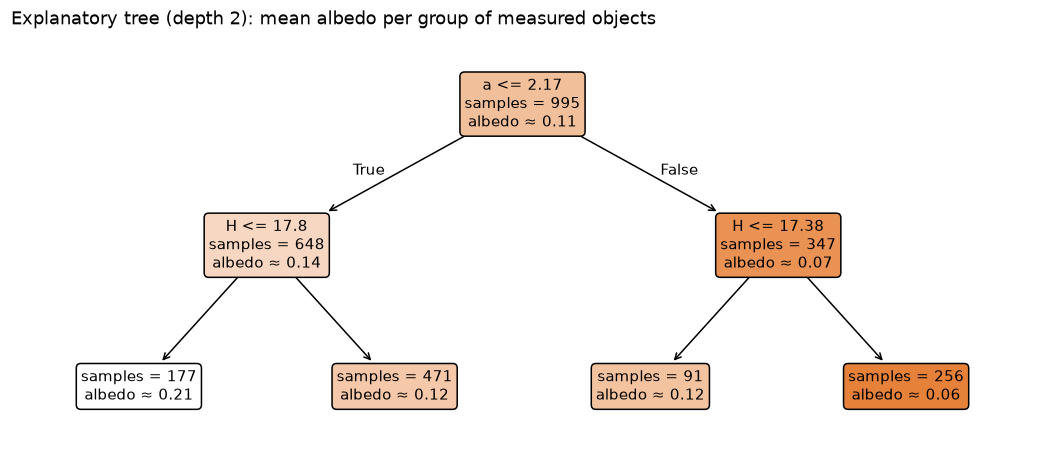

In [9]:
explain_cols = ["H", "a", "e", "i", "q", "ad"]
explainer = DecisionTreeRegressor(max_depth=2, min_samples_leaf=40, random_state=RANDOM_STATE)
explainer.fit(train[explain_cols], r_train)

fig, ax = plt.subplots(figsize=(12, 5))
artists = plot_tree(explainer, feature_names=explain_cols, filled=True, rounded=True,
                    impurity=False, precision=2, fontsize=10, ax=ax)
for t in artists:   # display the equivalent albedo instead of the log term
    txt = t.get_text()
    if "value = " in txt:
        head, val = txt.rsplit("value = ", 1)
        t.set_text(f"{head}albedo ≈ {term_to_albedo(float(val)):.2f}")
ax.set_title("Explanatory tree (depth 2): mean albedo per group of measured objects", loc="left")
save(fig, "albedo_explainer_tree")
plt.show()

**Reading the tree:** the first split is on the semi-major axis. Objects whose orbit extends far out (a > 2.17 AU) are clearly darker, especially among small ones (albedo ≈ 0.06). This is physically consistent: these objects tend to come from the outer main belt, rich in very dark carbonaceous asteroids. For them, the catalogue formula (albedo 0.14) **underestimates the diameter by about a third**.

## 5. Quantifying uncertainty

A single diameter is not enough for the PDCO: it needs to know **how large it could be**. We build an interval from the model's **cross-validated errors on the training set** (out-of-fold predictions), then check on the test set that it contains the expected share of true diameters.

- **90% interval**: between the 5% and 95% quantiles of the out-of-fold errors.
- **Pessimistic diameter**: the upper bound. It is the one to use for a "zero false negative" policy.

In [10]:
oof_rf = to_log_diameter(cross_val_predict(clone(grid.best_estimator_), train[FEATURES], r_train, cv=cv), train["H"])
oof_err = y_train - oof_rf          # true − predicted
q_low, q_high = np.quantile(oof_err, [0.05, 0.95])
print(f"90% interval: from ×{10**q_low:.2f} to ×{10**q_high:.2f} around the predicted diameter")

inside = (y_test >= best + q_low) & (y_test <= best + q_high)
print(f"Test coverage: {inside.mean():.1%} of the true diameters fall inside the interval (target: 90%)")

bins = pd.cut(test["H"], [0, 16, 18, 20, 22, 40], labels=["H ≤ 16", "16–18", "18–20", "20–22", "H > 22"])
coverage = (pd.DataFrame({"H bin": bins, "inside interval": inside, "error": best - y_test})
            .groupby("H bin", observed=True)
            .agg(objects=("error", "size"),
                 coverage=("inside interval", "mean"),
                 median_error_factor=("error", lambda e: 10 ** np.median(np.abs(e)))))
coverage.to_csv(REPORT_DIR / "coverage_by_h_bin.csv")
coverage

90% interval: from ×0.52 to ×2.14 around the predicted diameter
Test coverage: 88.0% of the true diameters fall inside the interval (target: 90%)


,objects,coverage,median_error_factor
H bin,,,
H ≤ 16,21,1.000,1.359
16–18,55,0.855,1.371
18–20,86,0.872,1.440
20–22,52,0.904,1.445
H > 22,35,0.829,1.532


## 6. Domain of validity: can the model predict small objects?

The model learned on mostly large objects. A random forest does not extend trends beyond its data: for an H larger than anything it has seen, it returns the value of its nearest leaves. This is a **cautious** property, unlike a linear model that would extend the slope to absurd albedos. We check it by plotting the predicted implied albedo over a range of H.

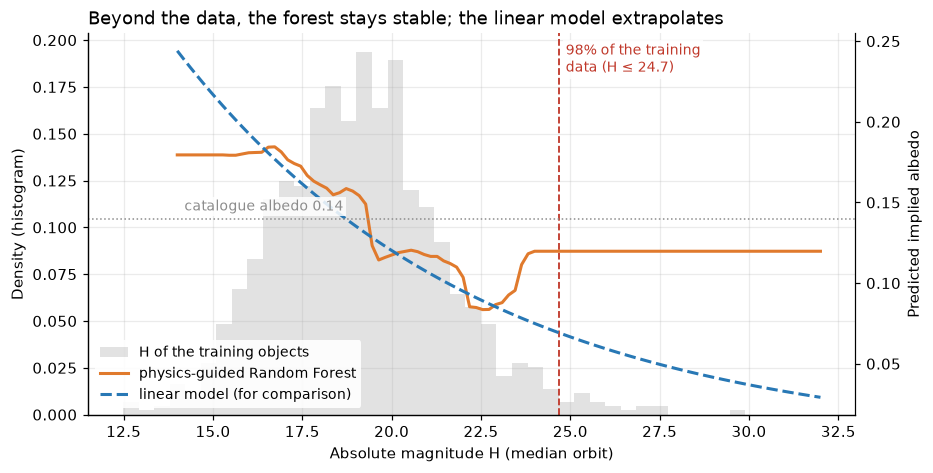

In [11]:
H_grid = np.linspace(14, 32, 100)
median_orbit = train[["a", "e", "i", "q", "ad"]].median()
grid_df = pd.DataFrame({"H": H_grid, **{c: median_orbit[c] for c in median_orbit.index},
                        "class": train["class"].mode()[0]})

lin_resid = pipe(LinearRegression()).fit(train[FEATURES], r_train)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(train["H"], bins=40, density=True, color=GREY, alpha=0.25, label="H of the training objects")
ax2 = ax.twinx()
ax2.plot(H_grid, term_to_albedo(grid.best_estimator_.predict(grid_df[FEATURES])), color=ORANGE, lw=2, label="physics-guided Random Forest")
ax2.plot(H_grid, term_to_albedo(lin_resid.predict(grid_df[FEATURES])), color=BLUE, lw=2, ls="--", label="linear model (for comparison)")
ax2.axhline(0.14, color=GREY, lw=1, ls=":")
ax2.text(14.2, 0.145, "catalogue albedo 0.14", color=GREY, fontsize=9, bbox=LABEL_BOX)
H_LIMIT = float(np.quantile(train["H"], 0.98))
ax.axvline(H_LIMIT, color=RED, ls="--", lw=1.2)
ax.text(H_LIMIT + 0.2, ax.get_ylim()[1] * 0.9, f"98% of the training\ndata (H ≤ {H_LIMIT:.1f})", color=RED, fontsize=9, bbox=LABEL_BOX)
ax.set_xlabel("Absolute magnitude H (median orbit)")
ax.set_ylabel("Density (histogram)")
ax2.set_ylabel("Predicted implied albedo")
ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax.set_title("Beyond the data, the forest stays stable; the linear model extrapolates", loc="left")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, frameon=True, framealpha=0.9, edgecolor="none", loc="lower left", fontsize=9)
save(fig, "validity_domain")
plt.show()

## 7. Applying the model to the whole catalogue

For each object:

- if the diameter is **measured**, we keep it;
- otherwise, we use the **physics-guided Random Forest prediction**, with its 90% interval;
- an `out_of_domain` flag marks objects smaller than 98% of the training objects: their prediction relies on very few examples.

This table feeds the energy computation and the priority score of step 7.

In [12]:
catalogue = pd.read_csv(sorted(RAW_DIR.glob("near_earth_asteroids_2025*.csv"))[0], low_memory=False)
cat = catalogue[["pdes", "H", "diameter_km", "diameter_is_estimated", "albedo"] + [c for c in FEATURES if c != "H"]].copy()

log_pred = np.asarray(to_log_diameter(grid.best_estimator_.predict(cat[FEATURES]), cat["H"]))
measured = ~cat["diameter_is_estimated"]

out = pd.DataFrame({
    "pdes": cat["pdes"],
    "H": cat["H"],
    "diameter_source": np.where(measured, "measured", "predicted"),
    "diameter_km": np.where(measured, cat["diameter_km"], 10 ** log_pred),
    "diameter_km_low": np.where(measured, cat["diameter_km"], 10 ** (log_pred + q_low)),
    "diameter_km_high": np.where(measured, cat["diameter_km"], 10 ** (log_pred + q_high)),
    "catalogue_diameter_km": cat["diameter_km"],
    "out_of_domain": (~measured) & (cat["H"] > H_LIMIT),
})
out.to_csv(PROCESSED_DIR / "catalogue_diameters.csv", index=False)
joblib.dump(grid.best_estimator_, PROCESSED_DIR / "rf_albedo_term.joblib")
(REPORT_DIR / "interval.json").write_text(json.dumps(
    {"q_low_dex": q_low, "q_high_dex": q_high, "H_limit": H_LIMIT, "best_params": grid.best_params_},
    indent=2), encoding="utf-8")

pred_rows = out[out["diameter_source"] == "predicted"]
summary = pd.DataFrame({
    "indicator": [
        "Objects in the catalogue",
        "Measured diameters (kept as is)",
        "Diameters predicted by the model",
        "of which out of domain (H > limit)",
        "Objects ≥ 140 m according to the catalogue",
        "Objects ≥ 140 m according to the model",
        "Objects ≥ 140 m according to the upper bound (pessimistic)",
    ],
    "value": [
        fmt(len(out)), fmt(measured.sum()), fmt(len(pred_rows)), fmt(out["out_of_domain"].sum()),
        fmt((out["catalogue_diameter_km"] >= 0.14).sum()),
        fmt((out["diameter_km"] >= 0.14).sum()),
        fmt((out["diameter_km_high"] >= 0.14).sum()),
    ],
})
summary.to_csv(REPORT_DIR / "catalogue_summary.csv", index=False)
summary

,indicator,value
0,Objects in the catalogue,"41,281"
1,Measured diameters (kept as is),"1,246"
2,Diameters predicted by the model,"40,035"
3,of which out of domain (H > limit),"16,883"
4,Objects ≥ 140 m according to the catalogue,"11,667"
5,Objects ≥ 140 m according to the model,"14,020"
6,Objects ≥ 140 m according to the upper bound (...,"20,059"


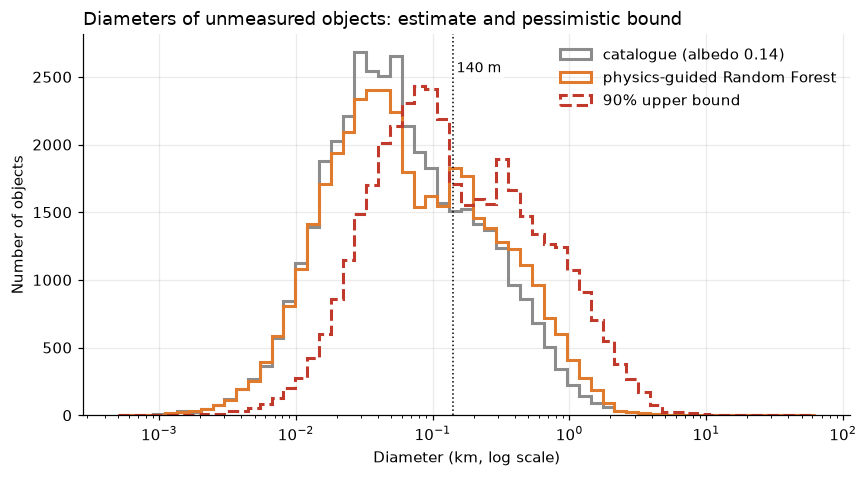

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.logspace(-3.3, 1.8, 60)
ax.hist(pred_rows["catalogue_diameter_km"], bins=bins, histtype="step", lw=2, color=GREY, label="catalogue (albedo 0.14)")
ax.hist(pred_rows["diameter_km"], bins=bins, histtype="step", lw=2, color=ORANGE, label="physics-guided Random Forest")
ax.hist(pred_rows["diameter_km_high"], bins=bins, histtype="step", lw=2, ls="--", color=RED, label="90% upper bound")
ax.axvline(0.14, color="black", lw=1, ls=":")
ax.text(0.15, ax.get_ylim()[1] * 0.9, "140 m", fontsize=9, bbox=LABEL_BOX)
ax.set_xscale("log")
ax.set_xlabel("Diameter (km, log scale)")
ax.set_ylabel("Number of objects")
ax.set_title("Diameters of unmeasured objects: estimate and pessimistic bound", loc="left")
ax.legend(frameon=False)
save(fig, "catalogue_diameters")
plt.show()

## Summary

| Question | Answer |
|---|---|
| Better than the catalogue formula? | **Yes, modestly**: the average error drops by about 9% and errors larger than a factor of 2 drop from 20% to 12% of objects. The albedo remains largely unpredictable from the orbit. |
| Random Forest or linear? | Equivalent accuracy on the test set; the forest is kept because it does not extrapolate absurd trends to small objects. |
| Why guide the model with physics? | A tree approximates the linear relation log D = f(H) poorly; by predicting only the albedo term, it keeps the exact law and learns only the unknown part. |
| What uncertainty? | 90% interval calibrated with cross-validation and checked on the test set. An estimated diameter can be off by a factor close to 2. |
| Main limitation | Measured objects are mostly large: 41% of the catalogue is smaller than 98% of the training objects and carries the `out_of_domain` flag. |
| Effect on the catalogue | The model considers objects slightly darker than 0.14 on average: more objects exceed 140 m than with the catalogue formula, and even more with the upper bound. |
| For step 7 | Use `diameter_km_high` (pessimistic) for prioritization, in line with the "zero false negative" policy; since energy scales with D³, the gap between the estimate and the upper bound is strongly amplified. |